# Tercera entrega · Proyecto de IA
## Modelo final y artefacto de despliegue: riesgo de mortalidad en UCI por sepsis

**Sofia Gomez Rodriguez · Emmanuel Escobar Santos · Victor Andres Martinez Preciado**
Universidad Autónoma de Occidente · Inteligencia Artificial · 2026-2

Este cuaderno es la **fuente del modelo que consume la aplicación desplegada** (`app.py`).
Parte de la entrega 2 (regresión logística L1, ventana 0 h, 11 variables) y hace cuatro cosas:

1. Reconstruye el modelo dentro de un único `Pipeline`, para que la imputación y el escalado
   se ajusten **solo con entrenamiento** y viajen junto al modelo al despliegue.
2. Vuelve a comparar candidatos (incluido **Naive Bayes**) con validación cruzada, sin mirar el test.
3. Evalúa el modelo final: discriminación, calibración, estratos de riesgo, utilidad clínica y
   comparación contra SOFA en la misma cohorte.
4. Exporta el artefacto (`models/modelo_sepsis.joblib`) y las métricas (`models/metricas.json`).

**Contenido**
1. Configuración y carga de datos
2. Variables y partición (idénticas a la entrega 2)
3. Pipeline de preprocesamiento sin fuga de datos
4. Comparación de candidatos
5. Modelo final: ajuste, coeficientes y calibración
6. Umbrales y estratos de riesgo
7. Resultados en el conjunto de prueba
8. Explicación por paciente
9. Exportación del artefacto

## 1. Configuración y carga de datos

In [1]:
import json, os, platform, warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEMILLA = 42                      # misma semilla de la entrega 2: reproduce la misma partición
np.random.seed(SEMILLA)
print("scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | numpy 2.5.3 | pandas 3.0.5


In [2]:
# Rutas. El cuaderno funciona igual dentro del repositorio (notebooks/) o suelto en Colab.
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUTA_CSV = Path(os.environ.get("SEPSIS_CSV", RAIZ / "data" / "CriticalData_Sepsis.csv"))
DIR_MODELOS = RAIZ / "models"
DIR_FIGURAS = RAIZ / "reports" / "figuras"
DIR_MODELOS.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

if not RUTA_CSV.exists():         # en Colab: se pide el archivo si no está en disco
    from google.colab import files
    subido = files.upload()
    RUTA_CSV = Path(next(iter(subido)))

df = pd.read_csv(RUTA_CSV)
df.columns = df.columns.str.strip()
print(df.shape)

(10000, 68)


In [3]:
# Estilo único para todas las figuras: azul = nuestro modelo, naranja = comparador (SOFA), gris = referencia.
AZUL, NARANJA, GRIS, TINTA, TINTA2, REJILLA = "#2a78d6", "#eb6834", "#898781", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#ffffff", "axes.facecolor": "#ffffff", "savefig.facecolor": "#ffffff",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "text.color": TINTA, "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110, "savefig.dpi": 200,
    "legend.frameon": False, "axes.axisbelow": True})

def c(x, d=3):
    """Número con coma decimal para rótulos de figuras."""
    return f"{x:.{d}f}".replace(".", ",")

# Nombres clínicos para los rótulos de las figuras.
ES = {"SepticShock": "Choque séptico", "VasopressorUse_0h": "Vasopresor al ingreso", "MAP_0": "PA media", "SOFA_0h": "SOFA",
      "DBP_0": "PA diastólica", "SBP_0": "PA sistólica", "Lactate_0h": "Lactato", "INR_0h": "INR", "Age": "Edad",
      "FrailtyScore": "Fragilidad", "InfectionSource_desconocido": "Foco desconocido", "InfectionSource_piel": "Foco piel",
      "InfectionSource_pulmonar": "Foco pulmonar", "InfectionSource_urinaria": "Foco urinario"}

def guardar(nombre):
    """Guarda la figura actual en reports/figuras y la muestra."""
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / f"{nombre}.png", bbox_inches="tight")
    plt.show()

## 2. Variables y partición (idénticas a la entrega 2)

Se conserva la decisión de negocio de la entrega 2: **ventana 0 h**. El modelo solo usa lo que el
intensivista ya conoce al ingreso a UCI, porque el valor clínico está en anticipar (la sepsis es
tiempo-dependiente) y porque una variable de 24 h no existe en el momento en que se consulta la herramienta.
En la sección 4 se verifica que agregar las demás variables no mejora la discriminación.

In [4]:
OBJETIVO = "MortalityInICU"
COLS_CAT = ["InfectionSource"]
COLS_BIN = ["SepticShock", "VasopressorUse_0h"]
COLS_CONT = ["MAP_0", "SOFA_0h", "DBP_0", "SBP_0", "Lactate_0h", "INR_0h", "Age", "FrailtyScore"]
COLS_NUM = ["SepticShock", "VasopressorUse_0h", "MAP_0", "SOFA_0h", "DBP_0", "SBP_0",
            "Lactate_0h", "INR_0h", "Age", "FrailtyScore"]          # mismo orden que la entrega 2
VARIABLES = COLS_CAT + COLS_NUM

datos = df.dropna(subset=[OBJETIVO]).reset_index(drop=True)          # 670 filas sin desenlace: no se pueden usar
X = datos[VARIABLES].copy()                                          # ¡crudo, con sus NaN!
y = datos[OBJETIVO].astype(int)

# Misma partición estratificada 75/25 y misma semilla: los pacientes de prueba son los de la entrega 2.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
print(f"Train {X_train.shape} | Test {X_test.shape} | mortalidad train {y_train.mean():.3f} / test {y_test.mean():.3f}")
print("\nFaltantes en train (%):")
print((X_train.isna().mean() * 100).round(1).to_string())

Train (6997, 11) | Test (2333, 11) | mortalidad train 0.465 / test 0.465

Faltantes en train (%):
InfectionSource      7.8
SepticShock          7.5
VasopressorUse_0h    6.6
MAP_0                7.1
SOFA_0h              6.8
DBP_0                6.5
SBP_0                7.2
Lactate_0h           7.5
INR_0h               7.0
Age                  7.2
FrailtyScore         7.1


## 3. Pipeline de preprocesamiento sin fuga de datos

**Qué cambia frente a la entrega 2 y por qué.** En la entrega 2 la imputación KNN se ajustó con los
9.330 pacientes *antes* de separar entrenamiento y prueba. Eso tiene dos problemas:

* **Fuga de datos:** los vecinos usados para imputar un paciente de entrenamiento podían ser pacientes de prueba.
* **Evaluación optimista:** el desempeño medido en prueba no correspondía del todo a pacientes nunca vistos.

La solución es meter todo en un `Pipeline`: `fit` aprende medias, desviaciones, vecinos y coeficientes
**solo con entrenamiento**, y ese mismo objeto se exporta.

**La imputación es un paso de entrenamiento, no de producción.** Existe porque el conjunto de datos trae
cerca de 7 % de faltantes por variable, y descartar esas filas dejaría menos de la mitad de los pacientes.
En la aplicación desplegada todos los campos son obligatorios: `src/modelo.py` aplica el escalado, el
one-hot y la regresión ya ajustados **saltando el imputador**, y rechaza cualquier paciente incompleto.
Con datos completos el imputador no modifica nada, así que ambos caminos dan exactamente el mismo resultado
(se verifica al final del cuaderno y en las pruebas automáticas). El modelo, las variables, los hiperparámetros
y la partición son los mismos de la entrega 2.

* **Numéricas:** `StandardScaler` → `KNNImputer(k=20, ponderado por distancia)`, el k elegido en la entrega 2.
  Se escala antes de imputar porque KNN trabaja con distancias. Las binarias imputadas quedan como valor
  fraccionario (proporción de vecinos con el evento), que es una forma honesta de representar la incertidumbre.
* **Categórica (`InfectionSource`):** imputación por moda + one-hot. En la entrega 2 se mostró que KNN no
  superaba al azar para esta variable (accuracy 0,23 frente a 0,20), así que no se justifica un imputador
  más complejo.

In [5]:
def preprocesador_knn(k=20):
    numericas = Pipeline([("escalar", StandardScaler()),
                          ("imputar", KNNImputer(n_neighbors=k, weights="distance"))])
    categoricas = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))])
    return ColumnTransformer([("num", numericas, COLS_NUM), ("cat", categoricas, COLS_CAT)],
                             verbose_feature_names_out=False)

def preprocesador_mediana():
    numericas = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    categoricas = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))])
    return ColumnTransformer([("num", numericas, COLS_NUM), ("cat", categoricas, COLS_CAT)],
                             verbose_feature_names_out=False)

def logistica_l1():
    """Regresión logística de la entrega 2: L1, C=0.1, clases balanceadas, solver liblinear.
    scikit-learn >= 1.8 reemplazó `penalty` por `l1_ratio`; se soportan ambas versiones."""
    comunes = dict(C=0.1, class_weight="balanced", solver="liblinear", max_iter=5000, random_state=SEMILLA)
    version = tuple(int(p) for p in sklearn.__version__.split(".")[:2])
    return LogisticRegression(l1_ratio=1, **comunes) if version >= (1, 8) else LogisticRegression(penalty="l1", **comunes)

## 4. Comparación de candidatos

Todos los candidatos se comparan con **validación cruzada estratificada repetida (5×3) sobre
entrenamiento**. El conjunto de prueba no interviene en la elección (en la entrega 2 la comparación se
hizo con el test; aquí se corrige). Se incluye **Naive Bayes gaussiano**, que asume que las variables
son independientes entre sí dado el desenlace y que cada una sigue una normal dentro de cada clase.

In [6]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1)

candidatos = {
    "Logística L1 + KNN (propuesto)": Pipeline([("pre", preprocesador_knn()), ("modelo", logistica_l1())]),
    "Logística L1 + mediana": Pipeline([("pre", preprocesador_mediana()), ("modelo", logistica_l1())]),
    "Naive Bayes gaussiano + KNN": Pipeline([("pre", preprocesador_knn()), ("modelo", GaussianNB())]),
    "Naive Bayes gaussiano + mediana": Pipeline([("pre", preprocesador_mediana()), ("modelo", GaussianNB())]),
    "Random forest (entrega 2)": Pipeline([("pre", preprocesador_mediana()), ("modelo", RandomForestClassifier(
        n_estimators=100, max_depth=4, min_samples_leaf=5, min_samples_split=50, max_features="log2",
        random_state=SEMILLA, n_jobs=-1))]),
    "Gradient boosting": Pipeline([("pre", preprocesador_mediana()), ("modelo", HistGradientBoostingClassifier(
        max_depth=2, learning_rate=0.03, max_iter=150, random_state=SEMILLA))]),
}

filas = []
for nombre, cand in candidatos.items():
    auc_cv = cross_val_score(cand, X_train, y_train, cv=cv_rep, scoring="roc_auc", n_jobs=-1)
    brier_cv = -cross_val_score(cand, X_train, y_train, cv=cv5, scoring="neg_brier_score", n_jobs=-1)
    cand.fit(X_train, y_train)
    auc_train = roc_auc_score(y_train, cand.predict_proba(X_train)[:, 1])
    filas.append({"modelo": nombre, "AUC CV": auc_cv.mean(), "± DE": auc_cv.std(), "AUC train": auc_train,
                  "sobreajuste (train − CV)": auc_train - auc_cv.mean(), "Brier CV": brier_cv.mean()})
comparacion = pd.DataFrame(filas).set_index("modelo").round(4)
comparacion

,AUC CV,± DE,AUC train,sobreajuste (train − CV),Brier CV
modelo,,,,,
Logística L1 + KNN (propuesto),0.5821,0.0134,0.5911,0.0090,0.2434
Logística L1 + mediana,0.5839,0.0134,0.5930,0.0091,0.2432
Naive Bayes gaussiano + KNN,0.5741,0.0175,0.5776,0.0034,0.2861
Naive Bayes gaussiano + mediana,0.5741,0.0171,0.5777,0.0037,0.2833
Random forest (entrega 2),0.5832,0.0135,0.6279,0.0447,0.2420
Gradient boosting,0.5834,0.0124,0.6236,0.0402,0.2422


In [7]:
# ¿Y si se usan TODAS las variables (0 h o 24 h) en lugar de las 11? Se comprueba que el techo es del dataset.
def auc_cv_todas(ventana_24h):
    desenlaces = ["HospitalMortality", "Mortality28Days", "Mortality90Days", "Mortality1YearPostDischarge"]
    Xa = datos.drop(columns=["PatientID", OBJETIVO, "APACHE II", "SAPSII"] + desenlaces)
    if not ventana_24h:                                    # ventana 0 h: se quitan mediciones posteriores al ingreso
        Xa = Xa[[c for c in Xa.columns if not any(s in c for s in ("_3h", "_6h", "24h"))]]
    Xa = pd.get_dummies(Xa).astype(float).loc[X_train.index]
    gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.03, max_iter=200, random_state=SEMILLA)
    return Xa.shape[1], cross_val_score(gb, Xa, y_train, cv=cv5, scoring="roc_auc").mean()

for etiqueta, v24 in [("Todas las variables, ventana 0 h", False), ("Todas las variables, hasta 24 h", True)]:
    p, auc = auc_cv_todas(v24)
    comparacion.loc[f"Gradient boosting · {etiqueta}", ["AUC CV"]] = round(auc, 4)
    print(f"{etiqueta}: {p} columnas → AUC CV {auc:.3f}")
auc_cv_todas_0h = float(comparacion.loc["Gradient boosting · Todas las variables, ventana 0 h", "AUC CV"])
auc_cv_todas_24h = float(comparacion.loc["Gradient boosting · Todas las variables, hasta 24 h", "AUC CV"])

Todas las variables, ventana 0 h: 58 columnas → AUC CV 0.569


Todas las variables, hasta 24 h: 72 columnas → AUC CV 0.566


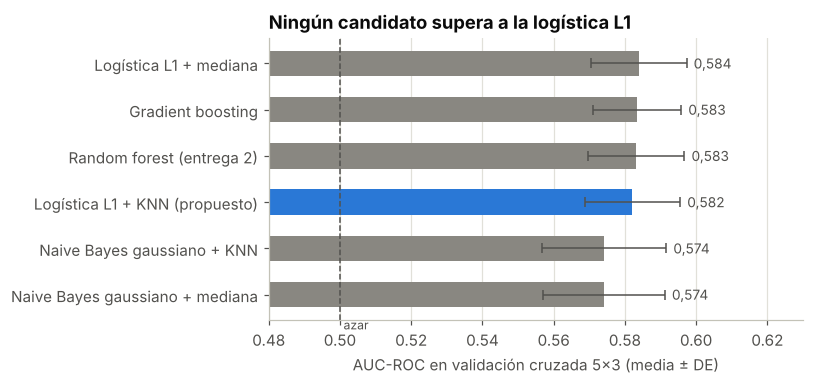

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
base = comparacion.dropna(subset=["± DE"]).sort_values("AUC CV")
colores = [AZUL if "propuesto" in n else GRIS for n in base.index]
ax.barh(base.index, base["AUC CV"], xerr=base["± DE"], color=colores, height=0.55,
        error_kw=dict(ecolor=TINTA2, lw=1, capsize=3))
for i, (v, s) in enumerate(zip(base["AUC CV"], base["± DE"])):
    ax.text(v + s + 0.002, i, c(v), va="center", fontsize=9, color=TINTA2)
ax.axvline(0.5, color=TINTA2, lw=1, ls="--"); ax.text(0.501, -0.75, "azar", fontsize=8, color=TINTA2)
ax.set_xlim(0.48, 0.63); ax.set_xlabel("AUC-ROC en validación cruzada 5×3 (media ± DE)")
ax.set_title("Ningún candidato supera a la logística L1"); ax.grid(axis="y", visible=False)
guardar("01_comparacion_modelos")

**Lectura.** Las diferencias de AUC entre candidatos (milésimas) son menores que la desviación entre
particiones (≈ 0,013): estadísticamente son indistinguibles. Naive Bayes queda por debajo en AUC y,
sobre todo, en Brier: su supuesto de independencia se viola (choque séptico, vasopresor y presiones
están correlacionados), así que cuenta la misma evidencia varias veces y entrega probabilidades
exageradas. Los modelos de árboles no ganan discriminación y muestran una brecha train−CV cuatro veces mayor.
Usar las 58 o 72 columnas tampoco ayuda: el techo (AUC ≈ 0,58) es del conjunto de datos, no del algoritmo.

**Decisión:** se mantiene la **regresión logística L1** de la entrega 2: iguala al mejor en
discriminación, casi no sobreajusta (brecha train−CV de 0,009 frente a 0,04 de los árboles) y es la única cuyas predicciones se pueden explicar a un
médico coeficiente por coeficiente.

## 5. Modelo final: ajuste, coeficientes y calibración

In [9]:
modelo = Pipeline([("pre", preprocesador_knn()), ("modelo", logistica_l1())])
modelo.fit(X_train, y_train)

pre, logit = modelo.named_steps["pre"], modelo.named_steps["modelo"]
NOMBRES = list(pre.get_feature_names_out())
escalador = pre.named_transformers_["num"].named_steps["escalar"]
desv = pd.Series(escalador.scale_, index=COLS_NUM)

coef = pd.DataFrame({"coef_por_DE": logit.coef_[0]}, index=NOMBRES)
coef["OR_por_DE"] = np.exp(coef["coef_por_DE"])
# Coeficiente en unidades originales: las numéricas se dividieron por su DE; las dummies no se escalaron.
coef["coef_por_unidad"] = coef["coef_por_DE"] / desv.reindex(coef.index).fillna(1.0)
coef["OR_por_unidad"] = np.exp(coef["coef_por_unidad"])
coef["DE_de_la_variable"] = desv.reindex(coef.index)
print(f"Intercepto: {logit.intercept_[0]:.4f} | variables con coeficiente ≠ 0: {(coef['coef_por_DE'] != 0).sum()} de {len(coef)}")
coef.sort_values("coef_por_DE", key=np.abs, ascending=False).round(4)

Intercepto: -0.0217 | variables con coeficiente ≠ 0: 10 de 14


,coef_por_DE,OR_por_DE,coef_por_unidad,OR_por_unidad,DE_de_la_variable
SepticShock,0.2904,1.3370,0.7104,2.0349,0.4088
InfectionSource_desconocido,0.1272,1.1357,0.1272,1.1357,NaN
VasopressorUse_0h,0.0650,1.0671,0.1343,1.1437,0.4839
Age,0.0550,1.0566,0.0034,1.0034,16.3443
INR_0h,0.0408,1.0416,0.0933,1.0978,0.4372
FrailtyScore,0.0354,1.0360,0.0234,1.0236,1.5144
InfectionSource_pulmonar,-0.0294,0.9711,-0.0294,0.9711,NaN
DBP_0,0.0248,1.0252,0.0016,1.0016,15.5845
Lactate_0h,0.0103,1.0104,0.0037,1.0037,2.8183
SOFA_0h,0.0019,1.0019,0.0014,1.0014,1.2963


**Cómo leer la tabla.** El modelo calcula `log-odds = intercepto + Σ coeficiente × variable estandarizada`
y lo convierte a probabilidad con la función sigmoide. `OR_por_unidad` es el factor por el que se
multiplican los *odds* de fallecer al subir la variable una unidad (o al pasar de "no" a "sí").
La penalización L1 lleva a cero los coeficientes redundantes: MAP y SBP no "desaparecen" clínicamente,
su información ya está en DBP, el choque séptico y el vasopresor.

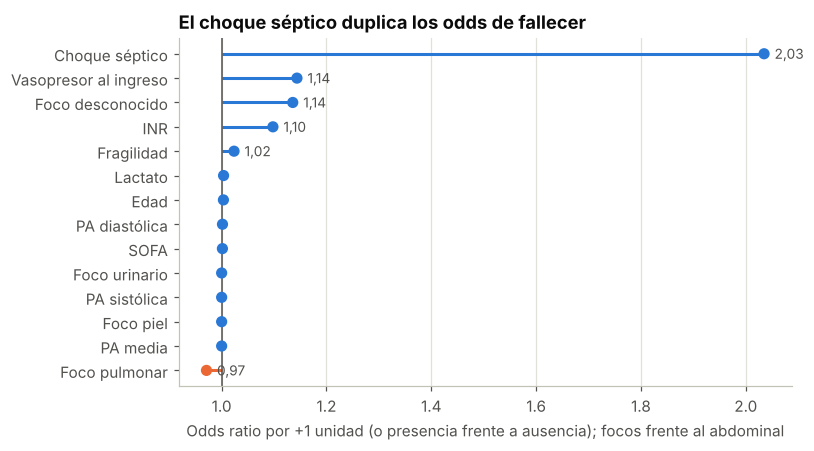

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
orden = coef["OR_por_unidad"].rename(index=ES).sort_values()
ax.hlines(orden.index, 1, orden.values, color=[AZUL if v >= 1 else NARANJA for v in orden.values], lw=2)
ax.scatter(orden.values, orden.index, color=[AZUL if v >= 1 else NARANJA for v in orden.values], s=40, zorder=3)
for nombre_v, v in orden.items():
    if abs(v - 1) > 0.02:
        ax.text(v + 0.02, nombre_v, c(v, 2), va="center", fontsize=9, color=TINTA2)
ax.axvline(1, color=TINTA2, lw=1)
ax.set_xlabel("Odds ratio por +1 unidad (o presencia frente a ausencia); focos frente al abdominal")
ax.set_title("El choque séptico duplica los odds de fallecer"); ax.grid(axis="y", visible=False)
guardar("02_odds_ratios")

### 5.1 Calibración

`class_weight="balanced"` hace que el modelo trate ambas clases como si fueran 50/50. Eso mejora la
sensibilidad, pero **desplaza las probabilidades hacia arriba** (la mortalidad real es 46,5 %, no 50 %).
Como la app muestra una probabilidad a un médico, se corrige con **calibración de Platt**: una regresión
logística de una sola variable, `p = sigmoide(a · log-odds + b)`, ajustada sobre predicciones de
validación cruzada del entrenamiento (cada paciente fue predicho por un modelo que no lo vio).
Es una transformación monótona: **no cambia el AUC ni el orden de los pacientes**, solo la escala.

In [11]:
sigmoide = lambda z: 1.0 / (1.0 + np.exp(-z))

z_cv = cross_val_predict(modelo, X_train, y_train, cv=cv5, method="decision_function")   # log-odds fuera de fold
platt = LogisticRegression(C=1e6, max_iter=1000).fit(z_cv.reshape(-1, 1), y_train)       # C enorme = sin regularizar
CAL_A, CAL_B = float(platt.coef_[0, 0]), float(platt.intercept_[0])
print(f"Calibración de Platt: a = {CAL_A:.4f}, b = {CAL_B:.4f}  (logit de la prevalencia = {np.log(y_train.mean()/(1-y_train.mean())):.4f})")

def riesgo(Xd):
    """Probabilidad calibrada de fallecer en UCI para un DataFrame con las 11 variables.
    (Aquí se admiten NaN porque se evalúa el conjunto de prueba, que trae faltantes; la app no los admite.)"""
    return sigmoide(CAL_A * modelo.decision_function(Xd) + CAL_B)

p_cv = sigmoide(CAL_A * z_cv + CAL_B)             # probabilidades calibradas fuera de fold (train)
p_test = riesgo(X_test)                           # probabilidades calibradas (test)
p_test_sin_calibrar = modelo.predict_proba(X_test)[:, 1]
print(f"Riesgo medio predicho en test: sin calibrar {p_test_sin_calibrar.mean():.3f} → calibrado {p_test.mean():.3f} | mortalidad real {y_test.mean():.3f}")
print(f"Rango de riesgos calibrados en test: {p_test.min():.3f} – {p_test.max():.3f}")

Calibración de Platt: a = 0.9858, b = -0.1467  (logit de la prevalencia = -0.1400)


Riesgo medio predicho en test: sin calibrar 0.501 → calibrado 0.465 | mortalidad real 0.465
Rango de riesgos calibrados en test: 0.353 – 0.683


## 6. Umbrales y estratos de riesgo

Con un AUC cercano a 0,60 no es defendible entregarle a un intensivista un veredicto binario
"fallece / sobrevive". La app muestra la **probabilidad calibrada** y la ubica en uno de tres **estratos**.
Los dos cortes se fijan con reglas explícitas sobre las predicciones de validación cruzada (nunca con el test):

* **Corte inferior (umbral de alerta):** el que detecta al **60 % de los fallecidos** (sensibilidad 0,60),
  el mismo punto de operación que se eligió en la entrega 2 priorizando el falso negativo.
* **Corte superior:** el que mantiene una **especificidad de 0,85**: quien lo supera está en el grupo de
  mayor riesgo con pocas falsas alarmas.

In [12]:
CORTE_BAJO = float(np.quantile(p_cv[y_train.values == 1], 0.40))    # 60 % de los fallecidos queda por encima
CORTE_ALTO = float(np.quantile(p_cv[y_train.values == 0], 0.85))    # 85 % de los sobrevivientes queda por debajo
ESTRATOS = ["Menor riesgo", "Riesgo intermedio", "Mayor riesgo"]

def estratificar(p):
    return pd.Categorical(np.where(p >= CORTE_ALTO, ESTRATOS[2], np.where(p >= CORTE_BAJO, ESTRATOS[1], ESTRATOS[0])),
                          categories=ESTRATOS, ordered=True)

def tabla_estratos(p, y_real):
    t = pd.DataFrame({"estrato": estratificar(p), "p": p, "y": np.asarray(y_real)})
    g = t.groupby("estrato", observed=False).agg(n=("y", "size"), fallecidos=("y", "sum"),
                                                  mortalidad_observada=("y", "mean"), riesgo_medio_predicho=("p", "mean"))
    g["% de pacientes"] = g["n"] / g["n"].sum() * 100
    return g

print(f"Corte inferior (alerta): {CORTE_BAJO:.3f} | Corte superior: {CORTE_ALTO:.3f}\n")
estratos_cv, estratos_test = tabla_estratos(p_cv, y_train), tabla_estratos(p_test, y_test)
print("Validación cruzada (train):"); print(estratos_cv.round(3).to_string())
print("\nPrueba:"); print(estratos_test.round(3).to_string())

Corte inferior (alerta): 0.428 | Corte superior: 0.517

Validación cruzada (train):
                      n  fallecidos  mortalidad_observada  riesgo_medio_predicho  % de pacientes
estrato                                                                                         
Menor riesgo       3161        1302                 0.412                  0.407          45.177
Riesgo intermedio  2355        1033                 0.439                  0.449          33.657
Mayor riesgo       1481         919                 0.621                  0.614          21.166

Prueba:
                      n  fallecidos  mortalidad_observada  riesgo_medio_predicho  % de pacientes
estrato                                                                                         
Menor riesgo       1058         427                 0.404                  0.406          45.349
Riesgo intermedio   770         337                 0.438                  0.449          33.005
Mayor riesgo        505         32

## 7. Resultados en el conjunto de prueba

El conjunto de prueba (2.333 pacientes) se usa **una sola vez**, aquí, con todo ya decidido.

In [13]:
def ic_bootstrap(funcion, *arreglos, n=2000, semilla=SEMILLA):
    """IC 95 % por bootstrap: se remuestrean pacientes con reemplazo y se recalcula la métrica."""
    rng = np.random.default_rng(semilla)
    arreglos = [np.asarray(a) for a in arreglos]
    valores = []
    for _ in range(n):
        idx = rng.integers(0, len(arreglos[0]), len(arreglos[0]))
        if len(np.unique(arreglos[0][idx])) < 2:
            continue
        valores.append(funcion(*[a[idx] for a in arreglos]))
    return [float(v) for v in np.percentile(valores, [2.5, 97.5])]

yt = y_test.values
auc = roc_auc_score(yt, p_test);              auc_ic = ic_bootstrap(roc_auc_score, yt, p_test)
auprc = average_precision_score(yt, p_test);  auprc_ic = ic_bootstrap(average_precision_score, yt, p_test)
brier = brier_score_loss(yt, p_test);         brier_ref = float(np.mean((yt - y_train.mean()) ** 2))
brier_sin_cal = brier_score_loss(yt, p_test_sin_calibrar)

# Pendiente e intercepto de calibración en test: lo ideal es pendiente 1 e intercepto 0.
logit_p = np.log(p_test / (1 - p_test))
recal = LogisticRegression(C=1e6, max_iter=1000).fit(logit_p.reshape(-1, 1), yt)
cal_pendiente, cal_intercepto = float(recal.coef_[0, 0]), float(recal.intercept_[0])

print(f"AUC-ROC  {auc:.3f}  IC95% [{auc_ic[0]:.3f}, {auc_ic[1]:.3f}]   (validación cruzada: {comparacion.iloc[0]['AUC CV']:.3f})")
print(f"AUPRC    {auprc:.3f}  IC95% [{auprc_ic[0]:.3f}, {auprc_ic[1]:.3f}]   (azar = prevalencia = {yt.mean():.3f})")
print(f"Brier    {brier:.4f}  (sin calibrar {brier_sin_cal:.4f}; predecir siempre la prevalencia {brier_ref:.4f})")
print(f"Calibración en test: pendiente {cal_pendiente:.3f}, intercepto {cal_intercepto:.3f}")

AUC-ROC  0.594  IC95% [0.571, 0.617]   (validación cruzada: 0.582)
AUPRC    0.566  IC95% [0.535, 0.598]   (azar = prevalencia = 0.465)
Brier    0.2400  (sin calibrar 0.2413; predecir siempre la prevalencia 0.2488)
Calibración en test: pendiente 1.144, intercepto 0.019


### 7.1 Comparación contra SOFA en la misma cohorte

SOFA al ingreso es el estándar que la médica asesora confirmó que se usa hoy. Se compara en los
pacientes de prueba que tienen SOFA registrado, y la diferencia de AUC se evalúa con bootstrap pareado.

n con SOFA: 2186 | AUC SOFA 0.564 [0.539, 0.587] | AUC modelo 0.595 | diferencia +0.031 IC95% [+0.007, +0.055]


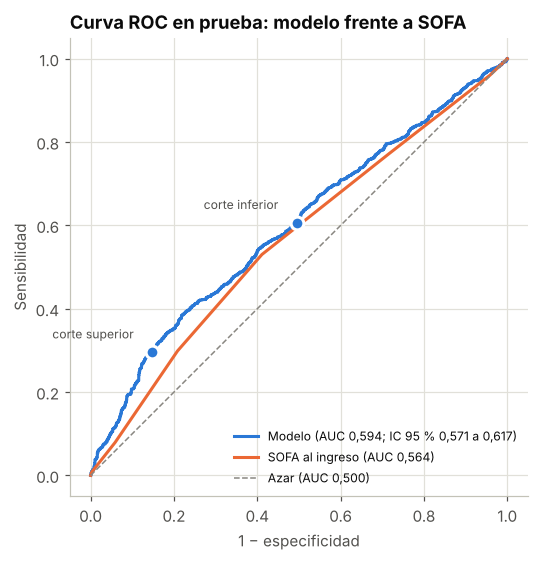

In [14]:
con_sofa = X_test["SOFA_0h"].notna().values
sofa = X_test.loc[con_sofa, "SOFA_0h"].values
auc_sofa = roc_auc_score(yt[con_sofa], sofa);            auc_sofa_ic = ic_bootstrap(roc_auc_score, yt[con_sofa], sofa)
auc_modelo_sub = roc_auc_score(yt[con_sofa], p_test[con_sofa])
dif = auc_modelo_sub - auc_sofa
dif_ic = ic_bootstrap(lambda a, b, c: roc_auc_score(a, b) - roc_auc_score(a, c), yt[con_sofa], p_test[con_sofa], sofa)
print(f"n con SOFA: {con_sofa.sum()} | AUC SOFA {auc_sofa:.3f} [{auc_sofa_ic[0]:.3f}, {auc_sofa_ic[1]:.3f}] | "
      f"AUC modelo {auc_modelo_sub:.3f} | diferencia {dif:+.3f} IC95% [{dif_ic[0]:+.3f}, {dif_ic[1]:+.3f}]")

fig, ax = plt.subplots(figsize=(5.6, 5.2))
fpr, tpr, _ = roc_curve(yt, p_test); fpr_s, tpr_s, _ = roc_curve(yt[con_sofa], sofa)
ax.plot(fpr, tpr, color=AZUL, lw=2, label=f"Modelo (AUC {c(auc)}; IC 95 % {c(auc_ic[0])} a {c(auc_ic[1])})")
ax.plot(fpr_s, tpr_s, color=NARANJA, lw=2, label=f"SOFA al ingreso (AUC {c(auc_sofa)})")
ax.plot([0, 1], [0, 1], color=GRIS, lw=1, ls="--", label="Azar (AUC 0,500)")
for corte, etiqueta in [(CORTE_BAJO, "corte inferior"), (CORTE_ALTO, "corte superior")]:
    pred = p_test >= corte
    ax.scatter(pred[yt == 0].mean(), pred[yt == 1].mean(), s=70, color=AZUL, edgecolor="#ffffff", lw=2, zorder=5)
    ax.annotate(etiqueta, (pred[yt == 0].mean(), pred[yt == 1].mean()), textcoords="offset points", xytext=(-12, 9), ha="right", fontsize=8, color=TINTA2)
ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad"); ax.set_aspect("equal")
ax.set_title("Curva ROC en prueba: modelo frente a SOFA"); ax.legend(loc="lower right", fontsize=8)
guardar("03_roc_modelo_vs_sofa")

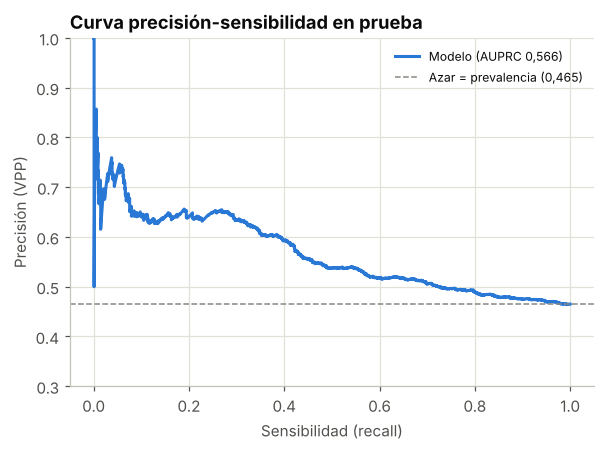

In [15]:
fig, ax = plt.subplots(figsize=(5.6, 4.2))
prec, rec, _ = precision_recall_curve(yt, p_test)
ax.plot(rec, prec, color=AZUL, lw=2, label=f"Modelo (AUPRC {c(auprc)})")
ax.axhline(yt.mean(), color=GRIS, lw=1, ls="--", label=f"Azar = prevalencia ({c(yt.mean())})")
ax.set_xlabel("Sensibilidad (recall)"); ax.set_ylabel("Precisión (VPP)"); ax.set_ylim(0.3, 1.0)
ax.set_title("Curva precisión-sensibilidad en prueba"); ax.legend(fontsize=8)
guardar("04_precision_recall")

### 7.2 Calibración: ¿se puede creer en el porcentaje?

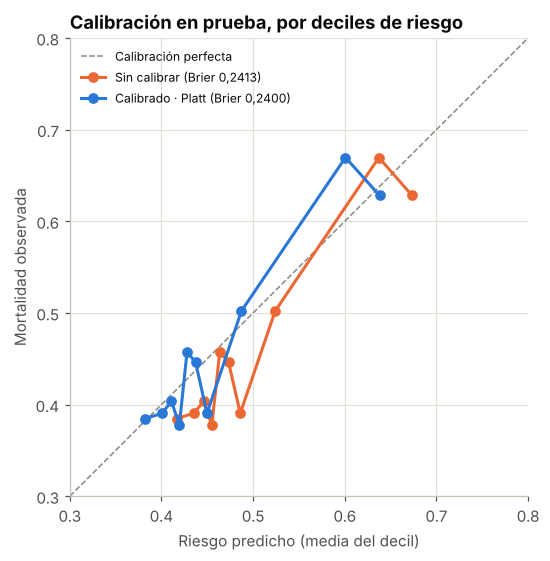

In [16]:
def curva_calibracion(p, y_real, n_grupos=10):
    t = pd.DataFrame({"p": p, "y": y_real})
    t["grupo"] = pd.qcut(t["p"].rank(method="first"), n_grupos, labels=False)
    return t.groupby("grupo").agg(predicho=("p", "mean"), observado=("y", "mean"), n=("y", "size"))

cal_antes, cal_despues = curva_calibracion(p_test_sin_calibrar, yt), curva_calibracion(p_test, yt)
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0.3, 0.8], [0.3, 0.8], color=GRIS, lw=1, ls="--", label="Calibración perfecta")
ax.plot(cal_antes["predicho"], cal_antes["observado"], "o-", color=NARANJA, lw=2, ms=6, label=f"Sin calibrar (Brier {c(brier_sin_cal, 4)})")
ax.plot(cal_despues["predicho"], cal_despues["observado"], "o-", color=AZUL, lw=2, ms=6, label=f"Calibrado · Platt (Brier {c(brier, 4)})")
ax.set_xlim(0.3, 0.8); ax.set_ylim(0.3, 0.8); ax.set_aspect("equal")
ax.set_xlabel("Riesgo predicho (media del decil)"); ax.set_ylabel("Mortalidad observada")
ax.set_title("Calibración en prueba, por deciles de riesgo"); ax.legend(loc="upper left", fontsize=8)
guardar("05_calibracion")

### 7.3 Estratos de riesgo y distribución de las predicciones

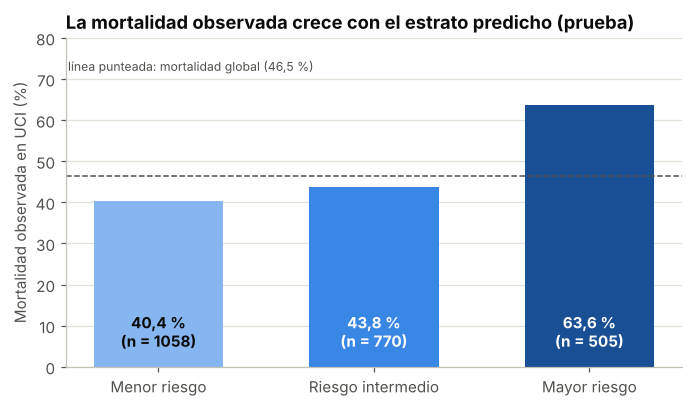

In [17]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
tonos = ["#86b6ef", "#3987e5", "#184f95"]                     # un solo tono, de claro a oscuro: magnitud ordenada
barras = ax.bar(ESTRATOS, estratos_test["mortalidad_observada"] * 100, color=tonos, width=0.6)
for b, (_, fila) in zip(barras, estratos_test.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, 4, f"{c(fila['mortalidad_observada']*100, 1)} %\n(n = {int(fila['n'])})",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color=TINTA if b is barras[0] else "white")
ax.axhline(yt.mean() * 100, color=TINTA2, lw=1, ls="--"); ax.text(-0.42, 72, f"línea punteada: mortalidad global ({c(yt.mean() * 100, 1)} %)", ha="left", fontsize=8, color=TINTA2)
ax.set_ylim(0, 80); ax.set_ylabel("Mortalidad observada en UCI (%)")
ax.set_title("La mortalidad observada crece con el estrato predicho (prueba)"); ax.grid(axis="x", visible=False)
guardar("06_estratos_riesgo")

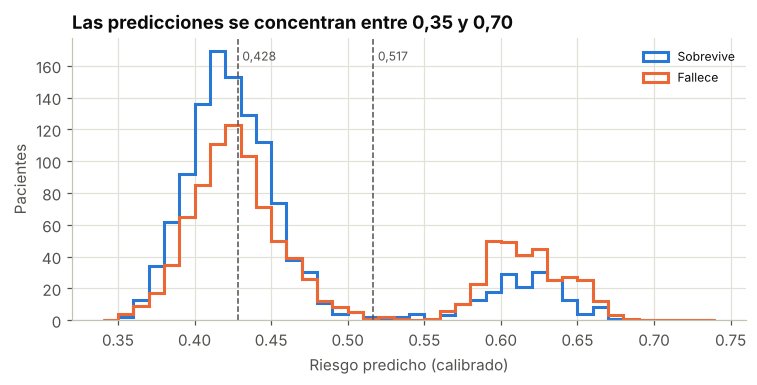

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.linspace(0.34, 0.74, 41)
ax.hist(p_test[yt == 0], bins=bins, color=AZUL, histtype="step", lw=2, label="Sobrevive")
ax.hist(p_test[yt == 1], bins=bins, color=NARANJA, histtype="step", lw=2, label="Fallece")
for corte in (CORTE_BAJO, CORTE_ALTO):
    ax.axvline(corte, color=TINTA2, lw=1, ls="--")
    ax.text(corte + 0.003, ax.get_ylim()[1] * 0.92, c(corte), fontsize=8, color=TINTA2)
ax.set_xlabel("Riesgo predicho (calibrado)"); ax.set_ylabel("Pacientes")
ax.set_title("Las predicciones se concentran entre 0,35 y 0,70"); ax.legend(fontsize=8)
guardar("07_distribucion_riesgos")

### 7.4 Matriz de confusión en los dos cortes

                               corte   VP   FP   FN    VN  sensibilidad  especificidad    VPP    VPN  accuracy     F1
Corte inferior (alerta)        0.428  658  617  427   631         0.606          0.506  0.516  0.596     0.553  0.558
Corte superior (mayor riesgo)  0.517  321  184  764  1064         0.296          0.853  0.636  0.582     0.594  0.404


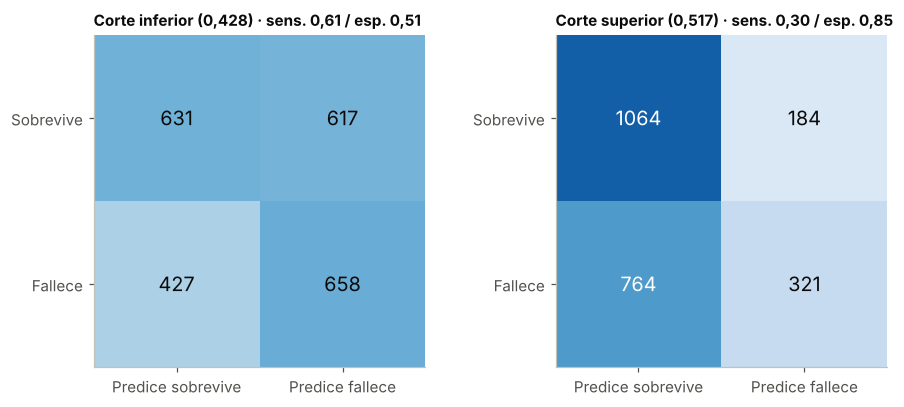

In [19]:
def metricas_en_corte(p, y_real, corte):
    vn, fp, fn, vp = confusion_matrix(y_real, (p >= corte).astype(int)).ravel()
    return {"corte": corte, "VP": int(vp), "FP": int(fp), "FN": int(fn), "VN": int(vn),
            "sensibilidad": vp / (vp + fn), "especificidad": vn / (vn + fp),
            "VPP": vp / (vp + fp), "VPN": vn / (vn + fn), "accuracy": (vp + vn) / len(y_real),
            "F1": 2 * vp / (2 * vp + fp + fn)}

m_bajo, m_alto = metricas_en_corte(p_test, yt, CORTE_BAJO), metricas_en_corte(p_test, yt, CORTE_ALTO)
tabla_cortes = pd.DataFrame([m_bajo, m_alto], index=["Corte inferior (alerta)", "Corte superior (mayor riesgo)"])
display(tabla_cortes.round(3)) if "display" in dir() else print(tabla_cortes.round(3).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(8.6, 3.8))
for ax, m, titulo in zip(ejes, [m_bajo, m_alto], ["Corte inferior", "Corte superior"]):
    mat = np.array([[m["VN"], m["FP"]], [m["FN"], m["VP"]]])
    ax.imshow(mat, cmap="Blues", vmin=0, vmax=1300)
    for (i, j), v in np.ndenumerate(mat):
        ax.text(j, i, f"{v}", ha="center", va="center", fontsize=13, color="white" if v > 700 else TINTA)
    ax.set_xticks([0, 1], ["Predice sobrevive", "Predice fallece"]); ax.set_yticks([0, 1], ["Sobrevive", "Fallece"])
    ax.set_title(f"{titulo} ({c(m['corte'])}) · sens. {c(m['sensibilidad'], 2)} / esp. {c(m['especificidad'], 2)}", fontsize=10); ax.grid(False)
guardar("08_matrices_confusion")

### 7.5 Utilidad clínica: curva de decisión

El **beneficio neto** responde la pregunta del negocio: *¿usar el modelo para decidir a quién intensificar
la vigilancia es mejor que vigilar a todos o a ninguno?* Para un umbral de decisión `pt`,
`beneficio neto = VP/n − FP/n × pt/(1 − pt)`: los verdaderos positivos suman y los falsos positivos restan,
ponderados por cuánto pesa una falsa alarma frente a un caso no detectado.

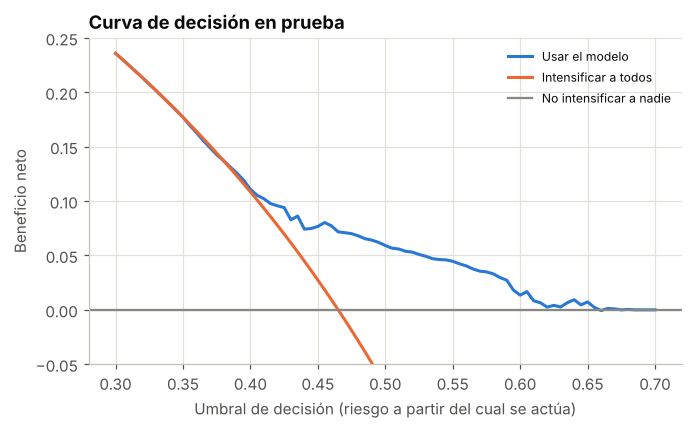

El modelo supera a ambas estrategias simples entre umbrales 0.39 y 0.65 (mejora máxima de beneficio neto: 0.072 en pt = 0.46)


In [20]:
umbrales = np.linspace(0.30, 0.70, 81)
def beneficio_neto(p, y_real, pt):
    pred = p >= pt
    return (pred & (y_real == 1)).sum() / len(y_real) - (pred & (y_real == 0)).sum() / len(y_real) * pt / (1 - pt)

bn_modelo = np.array([beneficio_neto(p_test, yt, t) for t in umbrales])
bn_todos = np.array([yt.mean() - (1 - yt.mean()) * t / (1 - t) for t in umbrales])
mejora = bn_modelo - np.maximum(bn_todos, 0)
rango_util = umbrales[mejora > 0.002]
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(umbrales, bn_modelo, color=AZUL, lw=2, label="Usar el modelo")
ax.plot(umbrales, bn_todos, color=NARANJA, lw=2, label="Intensificar a todos")
ax.axhline(0, color=GRIS, lw=1.5, label="No intensificar a nadie")
ax.set_ylim(-0.05, 0.25); ax.set_xlabel("Umbral de decisión (riesgo a partir del cual se actúa)"); ax.set_ylabel("Beneficio neto")
ax.set_title("Curva de decisión en prueba"); ax.legend(fontsize=8)
guardar("09_curva_decision")
print(f"El modelo supera a ambas estrategias simples entre umbrales {rango_util.min():.2f} y {rango_util.max():.2f} "
      f"(mejora máxima de beneficio neto: {mejora.max():.3f} en pt = {umbrales[mejora.argmax()]:.2f})")

### 7.6 Efecto de corregir la fuga de datos

In [21]:
# Se reproduce la entrega 2 tal cual (imputación con los 9.330 pacientes antes de partir) para cuantificar el efecto.
from sklearn.neighbors import KNeighborsClassifier
esc_all = StandardScaler(); Xs_all = esc_all.fit_transform(X[COLS_NUM])
Xn_all = pd.DataFrame(esc_all.inverse_transform(KNNImputer(n_neighbors=20, weights="distance").fit_transform(Xs_all)), columns=COLS_NUM)
Xn_all[COLS_BIN] = Xn_all[COLS_BIN].round().clip(0, 1)
for c in COLS_CONT:
    Xn_all[c] = Xn_all[c].clip(X[c].min(), X[c].max())
Xc_all = X[COLS_CAT].copy(); Z_all = StandardScaler().fit_transform(Xn_all); conocido = Xc_all["InfectionSource"].notna().values
Xc_all.loc[~conocido, "InfectionSource"] = KNeighborsClassifier(50, weights="distance").fit(Z_all[conocido], Xc_all.loc[conocido, "InfectionSource"]).predict(Z_all[~conocido])
X_e2 = pd.concat([Xc_all, Xn_all], axis=1)
pre_e2 = ColumnTransformer([("num", StandardScaler(), COLS_NUM), ("cat", OneHotEncoder(drop="first", sparse_output=False), COLS_CAT)])
modelo_e2 = Pipeline([("pre", pre_e2), ("modelo", logistica_l1())]).fit(X_e2.loc[X_train.index], y_train)
auc_e2 = roc_auc_score(y_test, modelo_e2.predict_proba(X_e2.loc[X_test.index])[:, 1])
print(f"AUC test entrega 2 (imputación antes de partir): {auc_e2:.3f}")
print(f"AUC test entrega 3 (todo dentro del Pipeline):   {auc:.3f}   → diferencia {auc - auc_e2:+.3f}")
print("Diferencia máxima entre coeficientes:", np.abs(modelo_e2.named_steps['modelo'].coef_[0] - logit.coef_[0]).max().round(3))

AUC test entrega 2 (imputación antes de partir): 0.598
AUC test entrega 3 (todo dentro del Pipeline):   0.594   → diferencia -0.004
Diferencia máxima entre coeficientes: 0.024


La fuga inflaba el AUC en unas milésimas: el efecto es pequeño porque la imputación no usa el desenlace,
pero el número honesto es el del Pipeline, y es el único que corresponde a lo que hará el modelo en producción.

## 8. Explicación por paciente

En un modelo lineal la explicación es exacta, sin aproximaciones: la contribución de cada variable al
log-odds es `coeficiente × (valor estandarizado − promedio de entrenamiento)`. Esto coincide con los
valores SHAP de `LinearExplainer` usados en la entrega 2, y la suma de contribuciones más el valor base
reproduce exactamente la salida del modelo. La app usa esta misma fórmula.

InfectionSource    desconocido
SepticShock                1.0
VasopressorUse_0h          1.0
MAP_0                     58.0
SOFA_0h                    3.0
DBP_0                     64.0
SBP_0                     64.0
Lactate_0h                 5.0
INR_0h                    1.47
Age                       88.0
FrailtyScore               7.0

Riesgo calibrado: 0.683


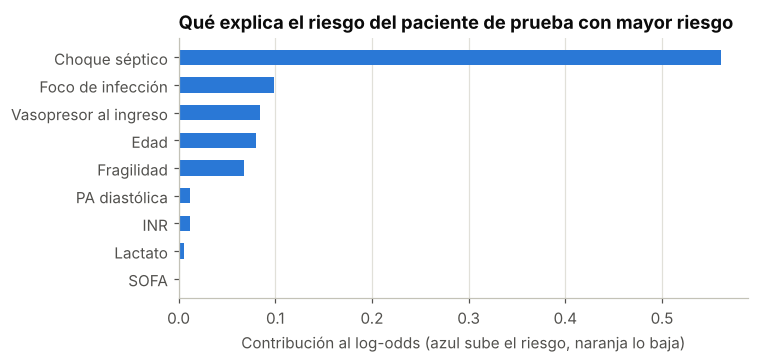

In [22]:
X_train_t = pd.DataFrame(pre.transform(X_train), columns=NOMBRES, index=X_train.index)
FONDO = X_train_t.mean()                                   # paciente "promedio" de entrenamiento
VALOR_BASE = float(logit.intercept_[0] + (logit.coef_[0] * FONDO.values).sum())

def explicar(fila):
    """Contribuciones (en log-odds) de cada variable para un paciente (DataFrame de una fila)."""
    xt = pd.Series(pre.transform(fila)[0], index=NOMBRES)
    contrib = pd.Series(logit.coef_[0], index=NOMBRES) * (xt - FONDO)
    assert np.isclose(VALOR_BASE + contrib.sum(), modelo.decision_function(fila)[0])      # la explicación cuadra
    return contrib

ejemplo = X_test.iloc[[int(np.argmax(p_test))]]            # paciente de prueba con mayor riesgo predicho
contrib = explicar(ejemplo)
focos = [n for n in NOMBRES if n.startswith("InfectionSource_")]          # las dummies del foco se suman en una sola barra
contrib = pd.concat([contrib.drop(focos), pd.Series({"Foco de infección": contrib[focos].sum()})]).rename(index=ES).sort_values(key=np.abs)
contrib = contrib[contrib.abs() > 1e-4]
print(ejemplo.T.to_string(header=False)); print(f"\nRiesgo calibrado: {riesgo(ejemplo)[0]:.3f}")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(contrib.index, contrib.values, color=[AZUL if v > 0 else NARANJA for v in contrib.values], height=0.55)
ax.axvline(0, color=TINTA2, lw=1); ax.set_xlabel("Contribución al log-odds (azul sube el riesgo, naranja lo baja)")
ax.set_title("Qué explica el riesgo del paciente de prueba con mayor riesgo"); ax.grid(axis="y", visible=False)
guardar("10_explicacion_paciente")

## 9. Exportación del artefacto

Se guarda **un solo archivo** con todo lo que la app necesita: el `Pipeline` ajustado, los parámetros de
calibración, los cortes, los rangos válidos de cada variable (para validar lo que digita el médico) y la
ficha de métricas. La app no reentrena ni recalcula nada: solo carga y predice.

> **Nota de despliegue:** la app no usa el imputador, pero este sigue dentro del `Pipeline` exportado y
> `KNNImputer` guarda la matriz de entrenamiento (6.997 pacientes × 10 variables estandarizadas, sin
> identificadores). Con datos reales de una clínica el artefacto debe tratarse como dato sensible
> (Ley 1581 de 2012) o exportarse sin ese paso.

In [23]:
rangos = {c: {"min": float(X_train[c].min()), "p01": float(X_train[c].quantile(0.01)), "mediana": float(X_train[c].median()),
              "p99": float(X_train[c].quantile(0.99)), "max": float(X_train[c].max()),
              "pct_faltante": float(X_train[c].isna().mean() * 100)} for c in COLS_NUM}
categorias = sorted(X_train["InfectionSource"].dropna().unique().tolist())

def a_dict(tabla):
    """Tabla → diccionario serializable (los NaN pasan a None para que el JSON sea válido)."""
    return {str(k): {c: (None if pd.isna(v) else float(v)) for c, v in fila.items()} for k, fila in tabla.iterrows()}

metricas = {
    "fecha_entrenamiento": datetime.now(timezone.utc).strftime("%Y-%m-%d"),
    "n_total": int(len(df)), "n_utilizable": int(len(datos)), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "mortalidad": float(y.mean()),
    "auc_cv": float(comparacion.iloc[0]["AUC CV"]), "auc_cv_de": float(comparacion.iloc[0]["± DE"]),
    "auc_test": float(auc), "auc_test_ic95": auc_ic, "auprc_test": float(auprc), "auprc_test_ic95": auprc_ic,
    "brier_test": float(brier), "brier_test_sin_calibrar": float(brier_sin_cal), "brier_referencia": brier_ref,
    "calibracion_pendiente": cal_pendiente, "calibracion_intercepto": cal_intercepto,
    "sofa": {"n": int(con_sofa.sum()), "auc": float(auc_sofa), "auc_ic95": auc_sofa_ic, "auc_modelo_misma_muestra": float(auc_modelo_sub),
             "diferencia": float(dif), "diferencia_ic95": dif_ic},
    "cortes": {"bajo": CORTE_BAJO, "alto": CORTE_ALTO},
    "en_corte_bajo": {k: float(v) for k, v in m_bajo.items()}, "en_corte_alto": {k: float(v) for k, v in m_alto.items()},
    "estratos_test": a_dict(estratos_test), "estratos_cv": a_dict(estratos_cv),
    "riesgo_min_test": float(p_test.min()), "riesgo_max_test": float(p_test.max()),
    "curva_decision": {"umbral_min_util": float(rango_util.min()), "umbral_max_util": float(rango_util.max()), "mejora_maxima": float(mejora.max())},
    "auc_test_entrega2_con_fuga": float(auc_e2),
    "comparacion_modelos": a_dict(comparacion),
    "auc_cv_todas_0h": auc_cv_todas_0h, "auc_cv_todas_24h": auc_cv_todas_24h,
}
artefacto = {
    "pipeline": modelo, "calibracion": {"a": CAL_A, "b": CAL_B}, "cortes": {"bajo": CORTE_BAJO, "alto": CORTE_ALTO},
    "estratos": ESTRATOS, "cols_cat": COLS_CAT, "cols_num": COLS_NUM, "cols_bin": COLS_BIN, "variables": VARIABLES,
    "categorias_foco": categorias, "nombres_transformados": NOMBRES, "fondo": FONDO.to_dict(), "valor_base": VALOR_BASE,
    "coeficientes": a_dict(coef), "intercepto": float(logit.intercept_[0]),
    "rangos": rangos, "metricas": metricas,
    "versiones": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
joblib.dump(artefacto, DIR_MODELOS / "modelo_sepsis.joblib", compress=3)
(DIR_MODELOS / "metricas.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
print("Artefacto:", DIR_MODELOS / "modelo_sepsis.joblib", f"({(DIR_MODELOS / 'modelo_sepsis.joblib').stat().st_size / 1024:.0f} KB)")

Artefacto: /home/claude/sepsis-uci-riesgo/models/modelo_sepsis.joblib (93 KB)


In [24]:
# Prueba de humo del artefacto: se recarga desde disco y debe reproducir las predicciones del cuaderno.
recargado = joblib.load(DIR_MODELOS / "modelo_sepsis.joblib")
z = recargado["pipeline"].decision_function(X_test)
p_recargado = sigmoide(recargado["calibracion"]["a"] * z + recargado["calibracion"]["b"])
assert np.allclose(p_recargado, p_test)
un_paciente = pd.DataFrame([{"InfectionSource": "pulmonar", "SepticShock": 1, "VasopressorUse_0h": 1, "MAP_0": 58, "SOFA_0h": 4,
                             "DBP_0": 45, "SBP_0": 84, "Lactate_0h": 4.8, "INR_0h": 1.6, "Age": 78, "FrailtyScore": 6}])[VARIABLES]
# Camino de producción: escalado + one-hot + logística, SIN pasar por el imputador (así lo hace src/modelo.py).
xt = np.concatenate([escalador.transform(un_paciente[COLS_NUM])[0],
                     pre.named_transformers_["cat"].named_steps["onehot"].transform(un_paciente[COLS_CAT].values)[0]])
z_sin_imputador = float(logit.decision_function(xt.reshape(1, -1))[0])
assert np.isclose(z_sin_imputador, modelo.decision_function(un_paciente)[0])
print(f"Predicciones reproducidas correctamente | Paciente completo de ejemplo → riesgo {riesgo(un_paciente)[0]:.3f} "
      f"({estratificar(riesgo(un_paciente))[0]}) | con y sin imputador: mismo resultado")

Predicciones reproducidas correctamente | Paciente completo de ejemplo → riesgo 0.631 (Mayor riesgo) | con y sin imputador: mismo resultado


## Conclusiones

* El modelo final es la **regresión logística L1 de la entrega 2**, ahora dentro de un `Pipeline` sin fuga
  de datos y con probabilidades calibradas. Ni Naive Bayes, ni los árboles, ni usar todas las variables la superan.
* La discriminación es **modesta pero real**: supera al azar y a SOFA al ingreso en la misma cohorte, y es
  estable entre validación cruzada y prueba (no hay sobreajuste).
* Las probabilidades están **bien calibradas**, pero solo cubren un rango estrecho (≈ 0,35–0,70): el modelo
  separa sobre todo a los pacientes con choque séptico del resto. Por eso el despliegue entrega estratos y
  explicación, no un veredicto.
* El techo de desempeño es **del conjunto de datos** (señal débil incluso en SOFA), coherente con la
  hipótesis de que los datos son sintéticos o fueron alterados al anonimizar. El pipeline y la app quedan
  listos para reentrenarse con datos reales sin cambiar código.